# Exercise: Doctor Who on holidays

*Doctor Who* is a British TV show. Since 2005, the BBC has shown a special episode almost every **Christmas Day**. Some years, it was on **New Year's Day**.

Do holiday episodes get more viewers? Today you use multiple regression to find out.

## Setup

In [2]:
library('tidymodels')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

## The data

Each row is one episode, from 2005 to 2022.

| column | meaning |
|---|---|
| `episode_title` | name of the episode |
| `type` | `episode` or `special` |
| `first_aired` | date the episode was first on TV |
| `uk_viewers` | UK viewers, in millions |
| `rating` | audience score, 0–100 |

Source: [TidyTuesday, 2023-11-28](https://github.com/rfordatascience/tidytuesday/tree/main/data/2023/2023-11-28) (from Wikipedia, via the `datardis` package).

We make two new columns:

- `holiday`: 1 if the episode aired on December 25 or January 1, 0 if not.
- `year`: the air date as a number, like 2010.5 for the middle of 2010. `decimal_date()` does this.

In [3]:
drwho <- read.csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2023/2023-11-28/drwho_episodes.csv')

drwho <- drwho |>
    mutate(
        first_aired = as.Date(first_aired),
        holiday = if_else(format(first_aired, '%m-%d') %in% c('12-25', '01-01'), 1, 0),
        year = lubridate::decimal_date(first_aired)
    )

drwho |> count(holiday)

  holiday n  
1 0       157
2 1        18

## 1. Look at the data

Plot `uk_viewers` (y-axis) against `first_aired` (x-axis). Color the points by `factor(holiday)`.

<details>
<summary>Hint</summary>

```R
ggplot(drwho, aes(x = first_aired, y = uk_viewers, color = factor(holiday))) +
    geom_point()
```

</details>

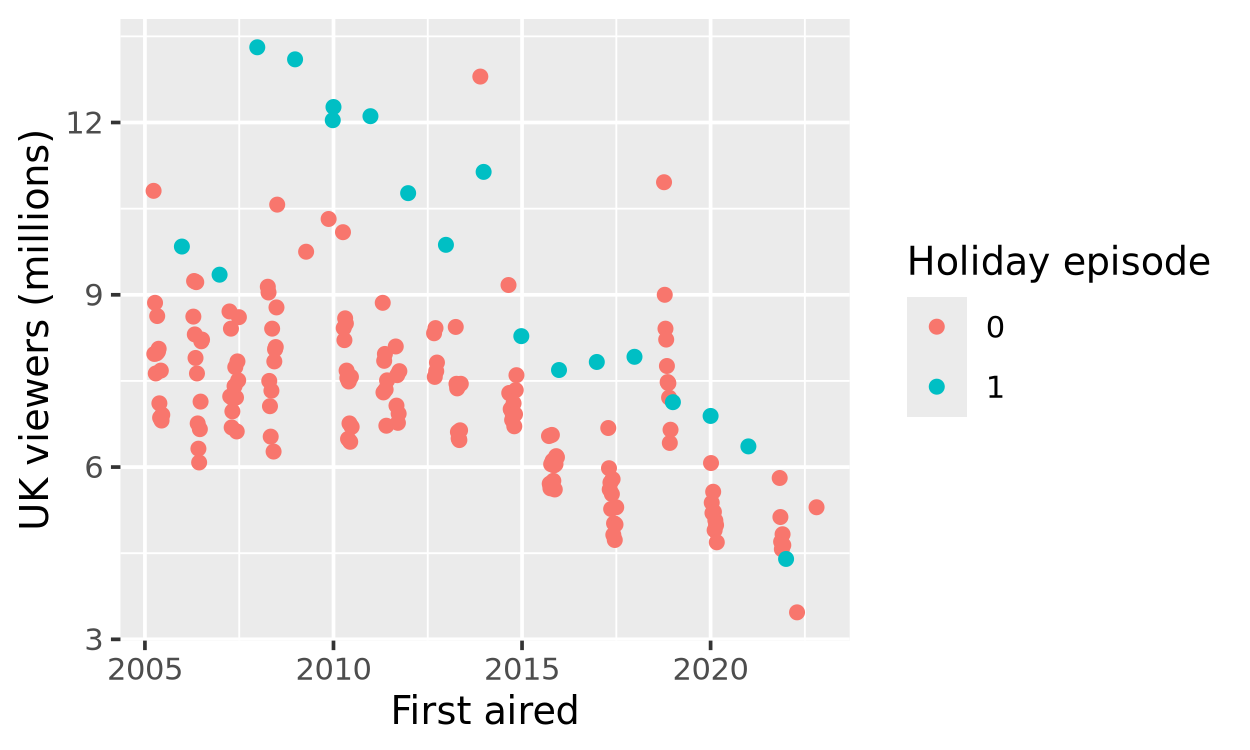

In [4]:
ggplot(drwho, aes(x = first_aired, y = uk_viewers, color = factor(holiday))) +
  geom_point() +
  labs(
    x = "First aired",
    y = "UK viewers (millions)",
    color = "Holiday episode"
  )

What happens to the number of viewers over time? Where are the holiday points?

## 2. One predictor

Fit `uk_viewers ~ holiday` with `linear_reg()`. Save it as `fit_one` and show `tidy(fit_one)`.

<details>
<summary>Hint</summary>

```R
fit_one <- linear_reg() |> fit(uk_viewers ~ holiday, data = drwho)

fit_one
```

</details>

In [5]:
fit_one <- linear_reg() |>
  fit(uk_viewers ~ holiday, data = drwho)

tidy(fit_one)

  term        estimate std.error statistic p.value      
1 (Intercept) 7.161083 0.1254197 57.096939 3.531246e-114
2 holiday     2.300028 0.3910647  5.881452  2.051807e-08

**Check:** the `holiday` estimate should be about 2.3. What does this number mean, in words?

In [ ]:
holiday episodes (Christmas Day or New Year’s Day) averaged about 2.3 million more UK viewers than non-holiday episodes. The intercept is the average for non-holiday episodes. Because holiday is 0/1, the coefficient is just the difference between the two group averages.

## 3. AI step: add `year`

Viewers go down over the years. We want to measure the marginal effect of `holiday` on viewership with a model that also factors in `year`.

Open a terminal and run `opencode`.

**Copy this prompt into opencode:**

```text
I am working in exercises/12-drwho-exercise.ipynb, with R and tidymodels.
The data frame drwho has a column uk_viewers (millions of viewers), a column
holiday (1 or 0), and a column year (the air date as a decimal year).

In the empty code cell in step 3, fit a linear regression of
uk_viewers ~ holiday + year with linear_reg(). Save it as fit_two and show
tidy(fit_two). Run the cell. Use tidymodels only. Do not change any other cells.
```

**Your assistant puts its code in the cell below and runs it.** Read the code. Does the formula have both `holiday` and `year`?

In [6]:
fit_two <- linear_reg() |>
  fit(uk_viewers ~ holiday + year, data = drwho)

tidy(fit_two)

  term        estimate    std.error   statistic p.value     
1 (Intercept) 379.4484005 38.72404194  9.798781 2.727092e-18
2 holiday       2.5295116  0.31721374  7.974155 2.050381e-13
3 year         -0.1849853  0.01924147 -9.613888 8.799150e-18

**Check:** the `holiday` estimate should be about 2.5. The `year` estimate should be about -0.19.

- What does the `year` estimate mean, in words?
- The `holiday` estimate changed from 2.3 to 2.5. Why? (Think about what "when the other predictor stays the same" means.)

In [ ]:
Holding holiday status the same, each additional year is associated with about 0.19 million (190,000) fewer UK viewers per episode, on average.

In [ ]:
In the first model, the holiday estimate compared holiday and non-holiday episodes from any year. Now it compares them while holding year constant, so it’s like comparing a holiday special to a regular episode that aired around the same time. Holiday specials aired mostly in the newer era, when viewership was generally lower. That lower era pulled their raw average down, so the first model slightly understated the holiday boost. Once year is accounted for, the holiday effect comes out a bit larger, at about 2.5 million extra viewers.

## 4. Plot the model

Make a grid with `crossing(year = 2005:2023, holiday = c(0, 1))`. Predict on the grid with `fit_two` and bind the grid to the predictions.

Plot the data with `year` on the x-axis. Add the predictions as lines, colored by `factor(holiday)`.

<details>
<summary>Hint</summary>

```R
grid <- crossing(year = 2005:2023, holiday = c(0, 1))

preds <- fit_two |>
    predict(new_data = grid) |>
    bind_cols(grid)

ggplot(drwho, aes(x = year, y = uk_viewers, color = factor(holiday))) +
    geom_point() +
    geom_line(data = preds, aes(y = .pred))
```

</details>

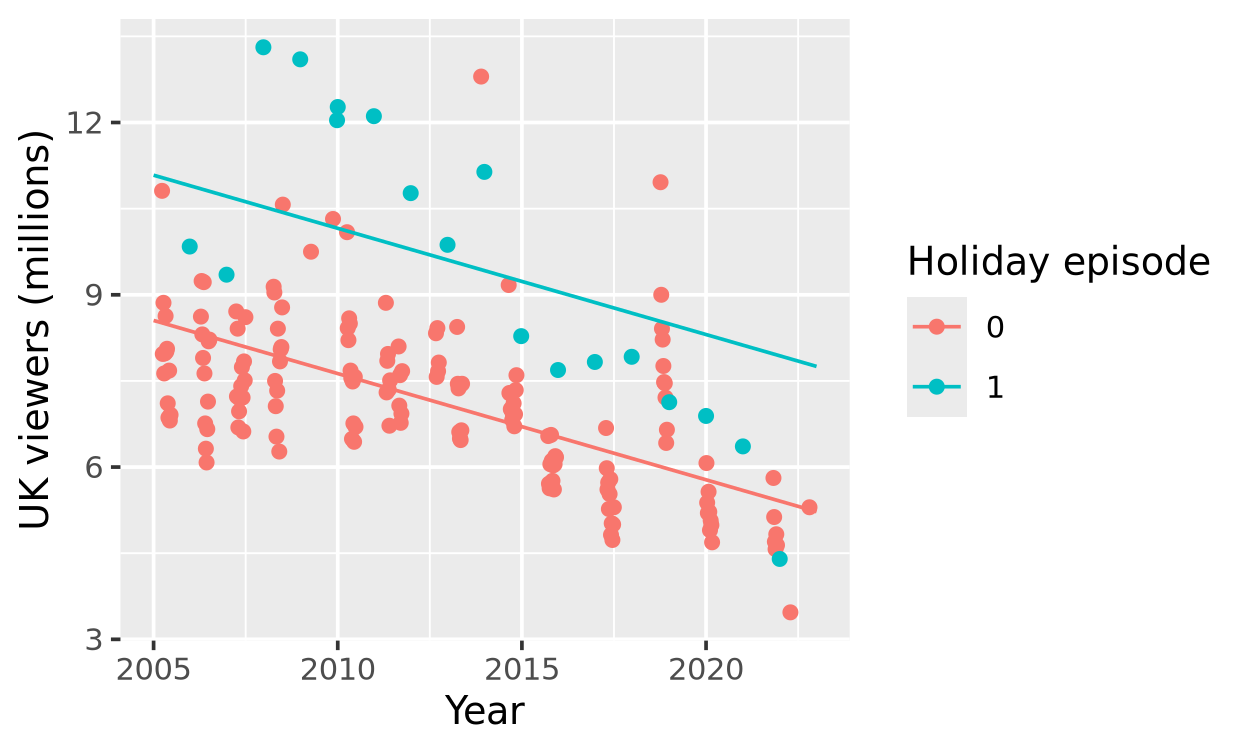

In [10]:
grid <- crossing(year = 2005:2023, holiday = c(0, 1))

preds <- grid |>
  bind_cols(predict(fit_two, new_data = grid))

ggplot(drwho, aes(x = year, y = uk_viewers, color = factor(holiday))) +
  geom_point() +
  geom_line(data = preds, aes(y = .pred)) +
  labs(x = "Year", y = "UK viewers (millions)", color = "Holiday episode")

**Check:** you should see two parallel lines that go down. The holiday line is about 2.5 million viewers higher.

## 5. Bonus: better or just bigger?

More people watch on holidays. But do they *like* the holiday episodes more?

Fit `rating ~ holiday + year`. Look at the `holiday` estimate.

In [11]:
fit_rating <- linear_reg() |>
  fit(rating ~ holiday + year, data = drwho)

tidy(fit_rating)

  term        estimate    std.error   statistic  p.value     
1 (Intercept) 854.2207048 82.84323597 10.3112909 1.029956e-19
2 holiday      -0.3030026  0.67862267 -0.4464965 6.558003e-01
3 year         -0.3827139  0.04116372 -9.2973595 6.440392e-17

**Check:** the `holiday` estimate should be close to 0 (about -0.3). Holiday episodes get more viewers, but not better scores.